# Homework 6 (due 16 November 2026 23:59:59)
### PHYS 440/540, Fall 2026


## Problem 1

Do the "Supervised Learning with scikit-learn Regression" chapter in DataCamp.

## Problem 2

Work through the various regression techniques that we talked about this week using a single example.  Fill in the blanks in the code cells below.  Where I have asked a question that requires an answer in words, I'm just looking for ~1 sentence.

---

## Problem 1

See Data Camp

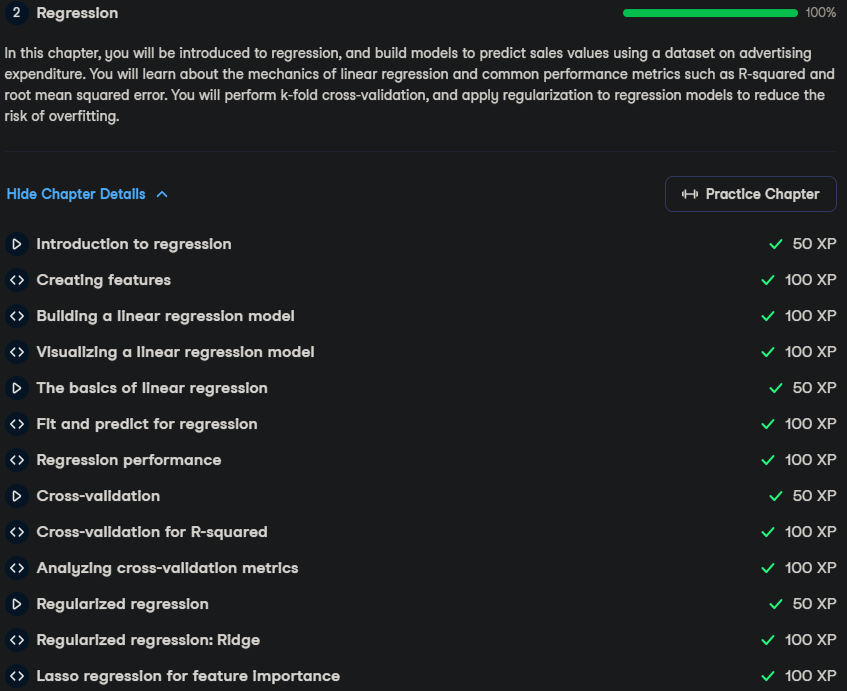

In [1]:
from IPython import display
display.Image("h6_dc.png")

## Problem 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge

Let's create a 2-D data set that is close to, but isn't quite linear.  We'll generate 500 sources.

In [4]:
N=500
D=2

X = 10*np.random.random((500,2)) # N points in D dimensions

dy = np.random.normal(loc=0,scale=2.0,size=500) # add heteroscedastic errors

#Simulate a distribution that isn't quite linear, but close.  Adding some noise
y = 80 + 0.6*X[:,0]**2 + -0.7*X[:,1]**2 + dy 

Now see what the data look like.  We have 2 inputs so we need 2, 1-D plots.

Text(0, 0.5, 'y')

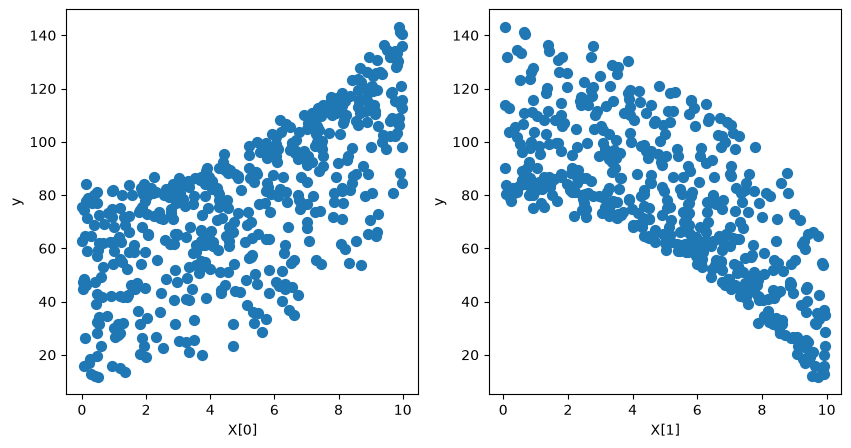

In [6]:
fig,ax = plt.subplots(1,2,figsize=(10, 5))
ax[0].scatter(X[:,0],y,s=50)
ax[0].set_xlabel('X[0]')
ax[0].set_ylabel('y')

#add the 2nd plot
ax[1].scatter(X[:,1],y,s=50)
ax[1].set_xlabel('X[1]')
ax[1].set_ylabel('y')

Now try fitting it with plain vanilla linear regression.

In [7]:
linreg = LinearRegression()
linreg.fit(X, y)
slopes = linreg.coef_
intercept = linreg.intercept_
print(intercept,slopes)

80.78582158893481 [ 6.14800976 -6.86497148]


Plot some of those trends.  We first need a grid of X values for the sake of plotting.

In [10]:
Xgrid0 = np.linspace(X[:,0].min(),X[:,0].max(),50)
ypred0 = slopes[0]*Xgrid0 + intercept

Xgrid1 = np.linspace(X[:,1].min(),X[:,1].max(),50) #Complete
ypred1 = slopes[1]*Xgrid1 + intercept #Complete

Now plot the data and the best fit.

Text(0, 0.5, 'y')

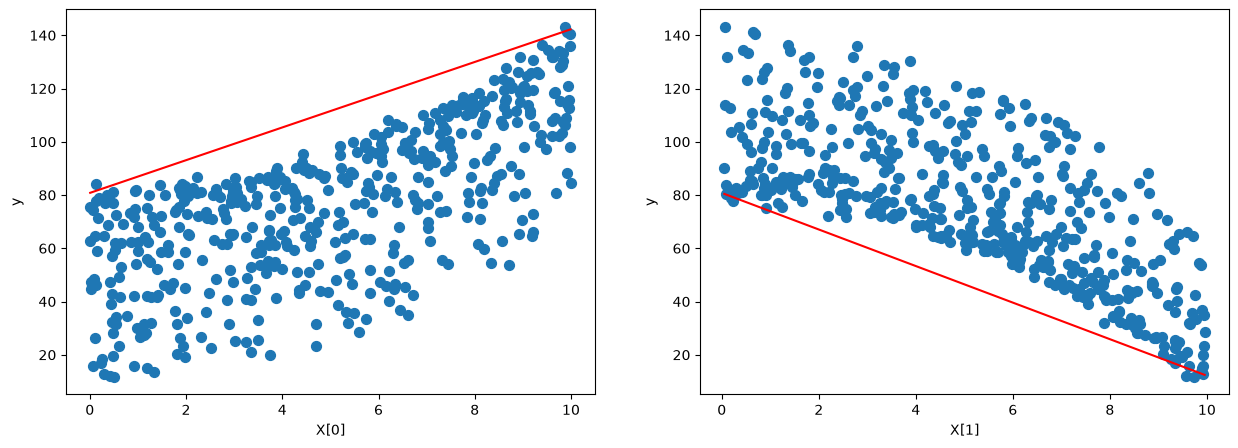

In [11]:
fig,ax = plt.subplots(1,2,figsize=(15, 5))
ax[0].scatter(X[:,0],y,s=50) #Data
ax[0].plot(Xgrid0,ypred0,"r-") #Best fit
ax[0].set_xlabel('X[0]')
ax[0].set_ylabel('y')

ax[1].scatter(X[:,1],y,s=50) #Data
ax[1].plot(Xgrid1,ypred1,"r-") #Best fit
ax[1].set_xlabel('X[1]')
ax[1].set_ylabel('y')

Why might the lines not go through the data?  The slopes look about right, but not the intercepts...  (Hint: Save this for after you've made the 3-D plot below.)


**Put 1-sentence answer here**

The data depends on both features and are quadratic rather than linear. Each 1D linear fit averages over the other feature.

Instead let's make a new two-dimensional prediction meshgrid `Xgrid` over the $2$-D feature space, use your best-fit model to predict the labels, and make a $3$-D interactive plot showing the data and your best-fit over the entire space.

**Note that the 3-D plotting will ONLY work in Jupyter Lab not in Jupyter Notebooks.**

In [12]:
uu, vv = np.meshgrid(Xgrid0, Xgrid1)
Xgrid = np.array([uu.flatten(), vv.flatten()]).T
print(Xgrid.shape)

(2500, 2)


In [26]:
ypred = linreg.predict(Xgrid)
print(ypred.shape)

(2500,)


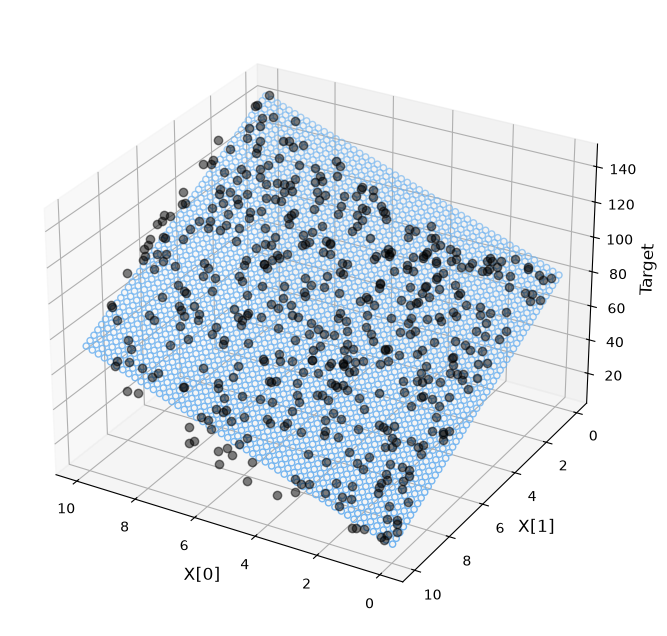

In [29]:
#Makes the plot interactive.  You can rotate it
### always do this line at the start 
### of an interactive plotting cell
%matplotlib inline

fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:,0], X[:,1], y, color='k', zorder=15, linestyle='none', marker='o', alpha=0.5)
ax.scatter(uu.flatten(), vv.flatten(), ypred, facecolor=(0,0,0,0), s=20, edgecolor='#70b3f0')
ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

In [30]:
### Always do this line before the start of a static plotting cell

%matplotlib inline

---

Now attempt a `GridSearchCV` procedure on the data to find the best `Ridge` regression hyper-parameters. Use the following `param_grid`:
```
ridge_params = {'alpha': [0.05,0.1,0.2,0.5,1.0], 'solver': ['svd', 'lsqr']}
```

In [31]:
from sklearn.linear_model import Ridge
ridge_params = {
'alpha': [0.05,0.1,0.2,0.5,1.0],
'solver': ['svd', 'lsqr']
}

In [32]:
ridgeGrid = GridSearchCV(Ridge(), param_grid = ridge_params)
ridgeGrid.fit(X,y,sample_weight=1/dy**2)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.05, 0.1, ...], 'solver': ['svd', 'lsqr']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, 

What are the `best_params_` and the `best_score_` from this? 

In [33]:
print(ridgeGrid.best_params_)
print(ridgeGrid.best_score_)

{'alpha': 1.0, 'solver': 'svd'}
0.734168830334049


Fit the data with the best options, and visualize interactively.

In [34]:
ridgeReg = Ridge(alpha=ridgeGrid.best_params_['alpha'],solver=ridgeGrid.best_params_['solver'])
ridgeReg.fit(X,y,sample_weight=1/dy**2)
ypredRidge = ridgeReg.predict(Xgrid)

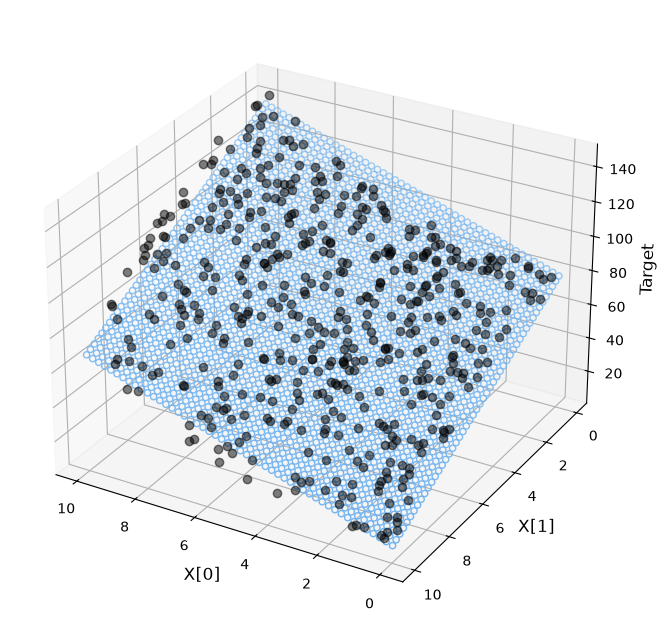

In [36]:
%matplotlib inline
fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:,0], X[:,1], y, color='k', zorder=15, linestyle='none', marker='o', alpha=0.5) #Data
ax.scatter(uu.flatten(), vv.flatten(), ypredRidge, facecolor=(0,0,0,0), s=20, edgecolor='#70b3f0') #Best fit
ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

In [ ]:
#turn off "notebook" plotting
%matplotlib inline

Try `RidgeCV` also; what cross-validated `alpha_` does it return, and does this agree with `GridSeachCV`?

RidgeCV picks in ridgeCv.alpha_, can differ because the cross-validation process is different

In [37]:
from sklearn.linear_model import RidgeCV

ridgeCv = RidgeCV(alphas=[0.05,0.1,0.2,0.5,1.0])
ridgeCv.fit(X,y,sample_weight=1/dy**2)
ridgeCv.alpha_

1.0

Running Ridge Regression in this case doesn't really make sense.   Why not?  

**Put ~1 sentence answer here**

The underlying relationship is quadratic, so Ridge regression lowers the linear coefficients and cannot model the curvature properly.

---

Now perform Nadaraya-Watson regression on the data, using a Gaussian kernel with a bandwidth of $0.2$. Visualize interactively as before. How does this look compared to previous models?

In [38]:
from astroML.linear_model import NadarayaWatson
nwreg = NadarayaWatson(kernel='gaussian', h=0.2)
nwreg.fit(X,y)
ypredNW = nwreg.predict(Xgrid)

c:\Users\sarda_hx81cfu\AppData\Local\Programs\Python\Python314\Lib\site-packages\astroML\linear_model\linear_regression_errors.py:10: UserWarning: LinearRegressionwithErrors requires PyMC3 to be installed
  warnings.warn('LinearRegressionwithErrors requires PyMC3 to be installed')


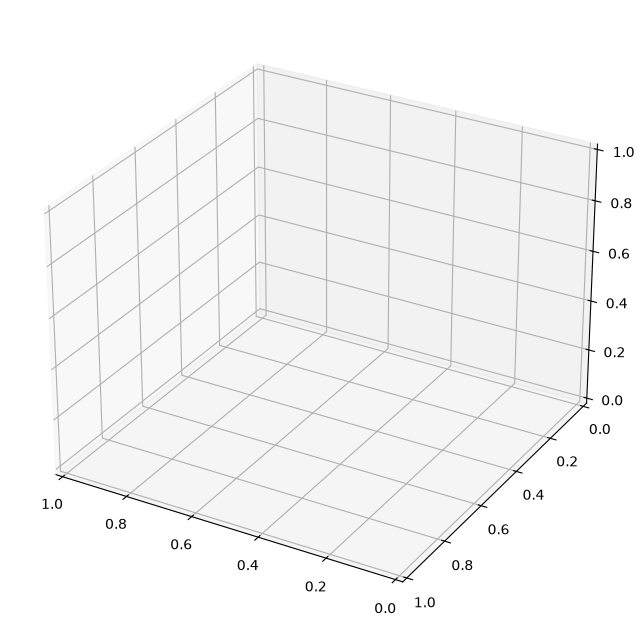

In [ ]:
%matplotlib widget
fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection='3d')

#Fill in from 3-D plot cells above and modify as needed.

ax.view_init(elev=28, azim=120)

In [41]:
#turn off "notebook" plotting
%matplotlib inline

How does this look compared to previous models?
    
***Put ~1 sentence answer here***

The Nadaraya-Watson model is different because it captures the nonlinear trend better than the linear and Ridge models, with smoothness varying from the bandwidth.

---

Now model the data using Gaussian process regression and the default kernel. Check what the fit looks like with and with and without uncertainties accounted for. *(Hint: GPR in `sklearn` takes an `alpha` parameter equal to `(dy/y)**2`.)*

In [42]:
from sklearn.gaussian_process import GaussianProcessRegressor
gp = GaussianProcessRegressor(alpha=(dy/y)**2)  #Do once with errors
#gp = GaussianProcessRegressor()  #And once without
gp.fit(X,y)
ypredGP, dypredGP = gp.predict(Xgrid, return_std=True)

c:\Users\sarda_hx81cfu\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


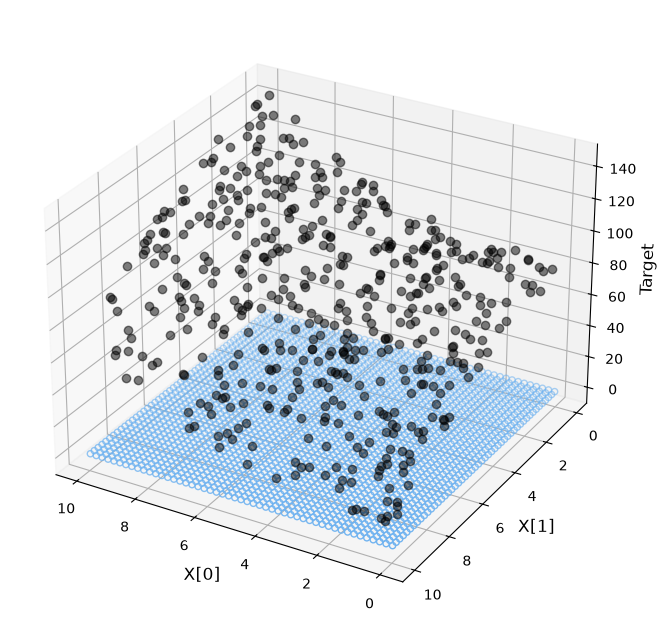

In [43]:
%matplotlib inline
fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:,0], X[:,1], y, color='k', zorder=15, linestyle='none', marker='o', alpha=0.5)
ax.scatter(uu.flatten(), vv.flatten(), ypredGP, facecolor=(0,0,0,0), s=20, edgecolor='#70b3f0')
ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

What difference do you see when including/excluding the uncertinties?
    
***Put ~1 sentence answer here***

Including the uncertainties gives the info about the Gaussian process and the noise from the measurements. Excluding uncertainties increases the noisy fluctuations.

---

Finally let's at polynomial fitting. Fit a $4$th degree polynomial to the data. Predict on the 2D meshgrid, and visualize interactively as before. How does this look compared to the linear model and GPR models?

In [44]:
from astroML.linear_model import PolynomialRegression
order = 4
poly = PolynomialRegression(degree=order) # fit Nth order polynomial
poly.fit(X,y)
ypredpoly = poly.predict(Xgrid)

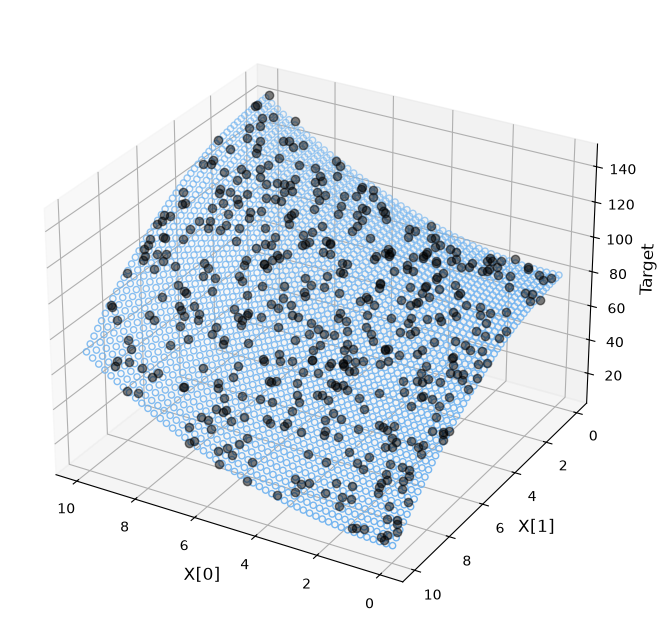

In [45]:
%matplotlib inline
fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:,0], X[:,1], y, color='k', zorder=15, linestyle='none', marker='o', alpha=0.5)
ax.scatter(uu.flatten(), vv.flatten(), ypredpoly, facecolor=(0,0,0,0), s=20, edgecolor='#70b3f0')
ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

In [ ]:
%matplotlib inline

Not bad!  Note that it does the polynomial regression in both dimensions of $X$.

Let's figure out the best fit polynomial model, the coefficients of that model and how well we might expect to do with unknown data.

First do a train-test split with a `train_size` of 80%.  Also split out a cross-validation set from the training set (leaving a somewhat smaller set to use for training).

In [46]:
from sklearn.model_selection import train_test_split
Xtrain, Xtestcv, ytrain, ytestcv = train_test_split(X, y, train_size=0.8, random_state=42)

Xtest, Xcv, ytest, ycv = train_test_split(Xtestcv,ytestcv, test_size=0.5, random_state=42)

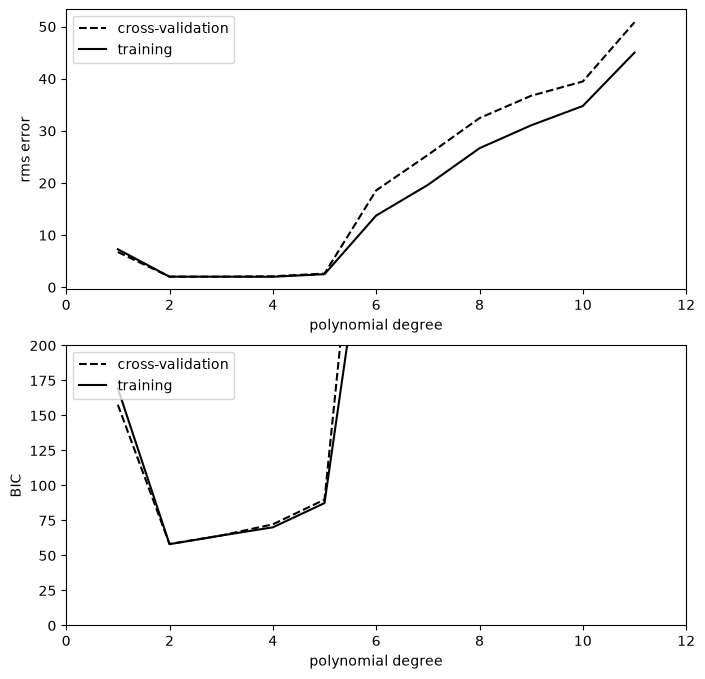

In [47]:
#import PolynomialRegression
from astroML.linear_model import PolynomialRegression

degrees = np.arange(1, 12)
training_err = np.zeros(degrees.shape)
crossval_err = np.zeros(degrees.shape)

fig = plt.figure(figsize=(8, 8))
for i,d in enumerate(degrees):
    #print(i,d)
    poly = PolynomialRegression(degree=d)

    poly.fit(Xtrain,ytrain)
    
    ypredTrain = poly.predict(Xtrain)
    ypredCV = poly.predict(Xcv)
    
    training_err[i] = np.sqrt(np.sum((ypredTrain - ytrain) ** 2)/len(ytrain))
    
    crossval_err[i] = np.sqrt(np.sum((ypredCV - ycv) ** 2)/len(ycv))
    

BIC_train = np.sqrt(len(y)) * training_err + degrees * np.log(len(y))
BIC_crossval = np.sqrt(len(y)) * crossval_err + degrees * np.log(len(y))

ax = fig.add_subplot(211)
ax.plot(degrees, crossval_err, '--k', label='cross-validation')
ax.plot(degrees, training_err, '-k', label='training')
#ax.plot(degrees, 0.1 * np.ones(degrees.shape), ':k')

ax.set_xlim(0, 12)

#ax.set_xlim(0, 14)
#ax.set_ylim(0, 0.8)

ax.set_xlabel('polynomial degree')
ax.set_ylabel('rms error')
ax.legend(loc=2)

ax = fig.add_subplot(212)
ax.plot(degrees, BIC_crossval, '--k', label='cross-validation')
ax.plot(degrees, BIC_train, '-k', label='training')

ax.set_xlim(0, 12)
ax.set_ylim(0, 200)

ax.legend(loc=2)
ax.set_xlabel('polynomial degree')
ax.set_ylabel('BIC')

plt.show()

Now use an 8th order model (so, not the best fit) to predict the error on unseen data.

In [48]:
poly = PolynomialRegression(degree=8)
poly.fit(Xtrain,ytrain)

ypredTest = poly.predict(Xtest)

In [49]:
test_err = np.sqrt(np.sum((ypredTest - ytest) ** 2)/len(ytest))
print(test_err)

22.489690953120856


What was the training error for that model? 

The error is ~26.67.

In [50]:
print(training_err[7])

26.674500074770606


What does that mean in terms of the importance of doing train-test splitting?

**Put ~1 sentence answer here.**

Adding a seperate test other than unseen data provides a better estimate for the generalized performance.